# Energy Calculation

In [38]:
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [39]:
from qss.magnetization import calculate_magnetization
from qss.distributions import prepare_2D_lattice_data
from tools.scientific_plot_v2 import ScientificPlotter, PlotConfig

plotter = ScientificPlotter()

## 2D Lattice

In [40]:
N = 100
t = -1
t_prim = 0.25
# t_prim = 0

kx = np.linspace(0, 2*np.pi*(N-1)/N, N+1) - np.pi
ky = np.linspace(0, 2*np.pi*(N-1)/N, N+1) - np.pi

e_k, _, _ = prepare_2D_lattice_data(kx, ky, t, t_prim)

## Magnetization

In [41]:
mu = Path("chemical_potential_results.csv")
if  mu.exists():
    mu_df = pd.read_csv(mu)
    n = np.unique(mu_df["n"])
    distro = np.unique(mu_df["distro"])
    k_BT = np.unique(mu_df["k_BT"])
    beta = 1/k_BT
    H_a = np.unique(mu_df["H_a"])
    
    if "magnetization" in mu_df.columns:
        magnetization_df = mu_df.set_index(["distro", "n", "k_BT", "H_a"])
    else:
        mu_df = mu_df.set_index(["distro", "n", "k_BT", "H_a"])
        magnetization_df = calculate_magnetization(mu_df, e_k)
        magnetization_df.to_csv("chemical_potential_results.csv")

else:
    raise("Lack of the calculated chemical potential! Please run notebook number 2")
magnetization_df

mu  iterations  converged      residual  \
distro n   k_BT   H_a                                                           
FD     0.8 0.0010 1.000000e-10 -0.327022          27       True  1.960847e-09   
                  1.396135e-10 -0.327022          27       True  1.960847e-09   
                  1.949194e-10 -0.327022          27       True  1.960847e-09   
                  2.721339e-10 -0.327022          27       True  1.960847e-09   
                  3.799357e-10 -0.327022          27       True  1.960847e-09   
...                                  ...         ...        ...           ...   
SSL    0.8 0.0001 2.632024e-01  1.136704          22       True  3.877301e-07   
                  3.674662e-01  1.032441          23       True  4.633583e-07   
                  5.130326e-01  0.886874          25       True  3.471706e-07   
                  7.162629e-01  0.683644          21       True  8.641096e-09   
                  1.000000e+00  0.399907          25       True  1.836688e-07   

                                magnetization  
distro n   k_BT   H_a                          
FD     0.8 0.0010 1.000000e-10   6.743666e-11  
                  1.396135e-10   9.415071e-11  
                  1.949194e-10   1.314471e-10  
                  2.721339e-10   1.835180e-10  
                  3.799357e-10   2.562160e-10  
...                                       ...  
SSL    0.8 0.0001 2.632024e-01   8.003137e-01  
                  3.674662e-01   8.003137e-01  
                  5.130326e-01   8.003137e-01  
                  7.162629e-01   8.003137e-01  
                  1.000000e+00   8.003137e-01  

[700 rows x 5 columns]

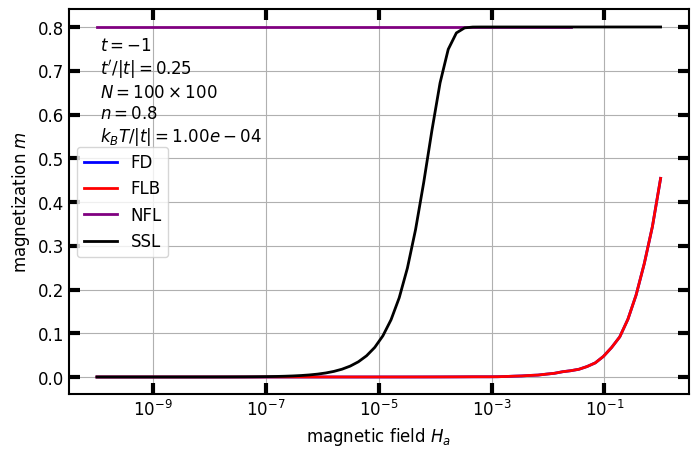

In [46]:
n_plot = n
beta_plot = 1/k_BT[0]
distro = ["FD","FLB","NFL","SSL"]
plotter.plot_scalar_result(
    results=magnetization_df,
    x_param="H_a",
    y_col="magnetization",
    y_label=r"magnetization $m$",
    fixed_params={"beta": beta_plot},
    distros=distro,
    subplots_param="n",
    subplots_vals=n_plot,
    cols=1,
    figsize=(8, 5),
    t_prim=t_prim,
    N=N,
    text_pos=(0.05, 0.93),
    xscale="log",
    blue_line=True
)
plt.show()